In [1]:
!pip install -q kagglehub
import glob, os, random
from collections import Counter
import numpy as np, matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"

import kagglehub
folder = kagglehub.dataset_download("faizalhajamohideen/uthcdtamil-handwritten-database")

files = [f for f in glob.glob(folder + "/**/*", recursive=True)
         if f.lower().endswith((".bmp", ".png", ".jpg", ".tif", ".tiff"))]

# Each letter has its own folder. Keep only 5 letters for a clean demo.
NUM_LETTERS = 5
letter_of = lambda f: os.path.basename(os.path.dirname(f))
chosen = [name for name, _ in Counter(map(letter_of, files)).most_common(NUM_LETTERS)]
files = [f for f in files if letter_of(f) in chosen]
print("Letters (folder names):", chosen, "|", len(files), "images")

Using Colab cache for faster access to the 'uthcdtamil-handwritten-database' dataset.
Letters (folder names): ['train', 'Train', 'test', 'Test', '080'] | 366776 images


Training images: torch.Size([366776, 1, 32, 32])


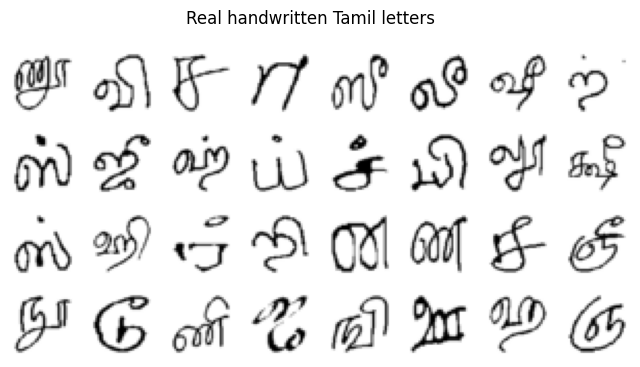

In [3]:
def clean(path):
    img = np.array(Image.open(path).convert("L"))
    if img.mean() > 127:
        img = 255 - img                                   # ink white, background black
    ys, xs = np.where(img > 64)
    img = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]   # crop to the ink
    side = int(max(img.shape) * 1.2)                      # square canvas with a margin
    canvas = np.zeros((side, side), dtype=np.uint8)
    y0, x0 = (side - img.shape[0]) // 2, (side - img.shape[1]) // 2
    canvas[y0:y0 + img.shape[0], x0:x0 + img.shape[1]] = img   # centre the letter
    small = np.array(Image.fromarray(canvas).resize((32, 32), Image.BILINEAR), dtype=np.float32)
    return small / 127.5 - 1                              # scale to [-1, 1]

images = []
for f in files:
    try:
        images.append(clean(f))
    except ValueError:                                    # skip blank images
        pass

data = torch.tensor(np.array(images)).unsqueeze(1)       # shape: (N, 1, 32, 32)
print("Training images:", data.shape)

def show(imgs, title):
    imgs = imgs.detach().cpu().view(-1, 32, 32)[:32]
    fig, axes = plt.subplots(4, 8, figsize=(8, 4))
    for ax, im in zip(axes.flat, imgs):
        ax.imshow(-im, cmap="gray"); ax.axis("off")        # show as dark ink on white
    fig.suptitle(title); plt.show()

show(data[torch.randperm(len(data))], "Real handwritten Tamil letters")

In [4]:
NOISE = 64

generator = nn.Sequential(
    nn.Linear(NOISE, 128 * 8 * 8), nn.ReLU(),
    nn.Unflatten(1, (128, 8, 8)),                                     # 8x8 sketch
    nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),   # -> 16x16
    nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1), nn.Tanh(),                         # -> 32x32
).to(device)

discriminator = nn.Sequential(
    nn.Conv2d(1, 64, 4, stride=2, padding=1), nn.LeakyReLU(0.2),                          # -> 16x16
    nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),   # -> 8x8
    nn.Flatten(), nn.Linear(128 * 8 * 8, 1),                                              # one score
).to(device)

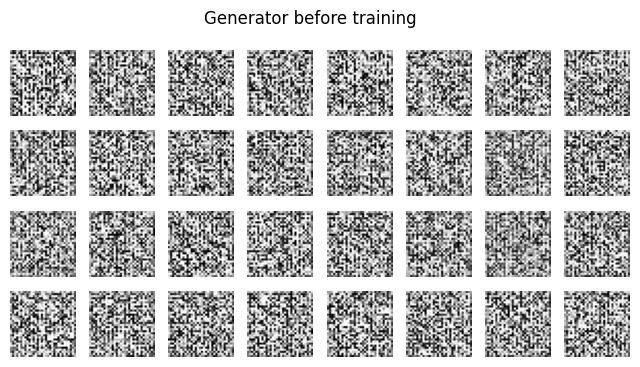

In [5]:
show(generator(torch.randn(32, NOISE, device=device)), "Generator before training")

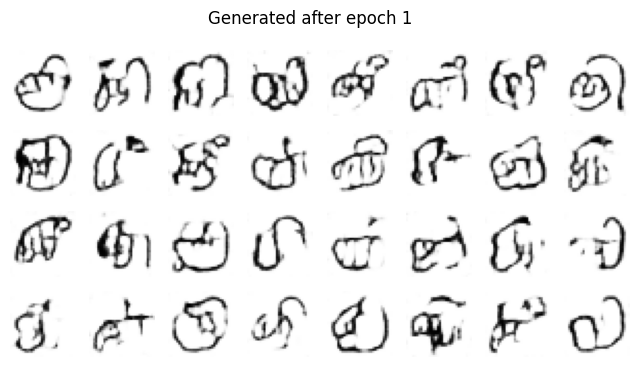

Epoch  10 | discriminator loss 0.37 | generator loss 4.88
Epoch  20 | discriminator loss 0.35 | generator loss 5.15


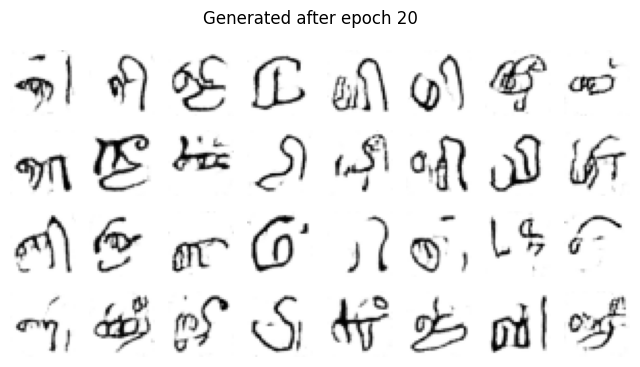

Epoch  30 | discriminator loss 0.35 | generator loss 4.93
Epoch  40 | discriminator loss 0.42 | generator loss 4.76
Epoch  50 | discriminator loss 0.35 | generator loss 5.38
Epoch  60 | discriminator loss 0.35 | generator loss 5.96
Epoch  70 | discriminator loss 0.35 | generator loss 5.22
Epoch  80 | discriminator loss 0.45 | generator loss 4.76
Epoch  90 | discriminator loss 0.37 | generator loss 4.70
Epoch 100 | discriminator loss 0.35 | generator loss 5.77


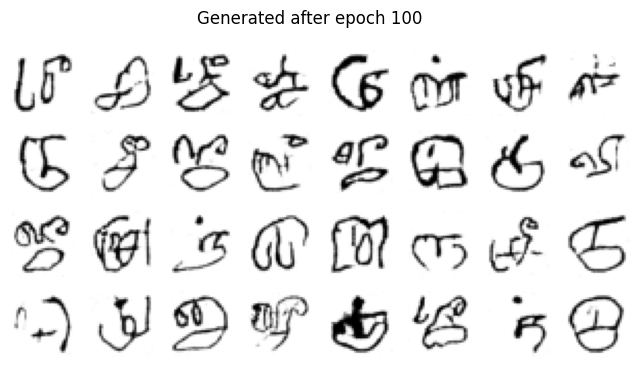

In [6]:
loss_fn = nn.BCEWithLogitsLoss()
opt_G = torch.optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))
loader = torch.utils.data.DataLoader(data, batch_size=64, shuffle=True, drop_last=True)
EPOCHS = 100

for epoch in range(EPOCHS):
    for real in loader:
        real = real.to(device)
        n = len(real)
        fake = generator(torch.randn(n, NOISE, device=device))

        # 1. Discriminator: real -> 0.9, fake -> 0
        d_loss = (loss_fn(discriminator(real), torch.full((n, 1), 0.9, device=device)) +
                  loss_fn(discriminator(fake.detach()), torch.zeros(n, 1, device=device)))
        opt_D.zero_grad(); d_loss.backward(); opt_D.step()

        # 2. Generator: make the discriminator say "real" for fakes
        g_loss = loss_fn(discriminator(fake), torch.ones(n, 1, device=device))
        opt_G.zero_grad(); g_loss.backward(); opt_G.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:3d} | discriminator loss {d_loss.item():.2f} | generator loss {g_loss.item():.2f}")
    if epoch + 1 in (1, 20, EPOCHS):
        generator.eval()
        show(generator(torch.randn(32, NOISE, device=device)), f"Generated after epoch {epoch + 1}")
        generator.train()

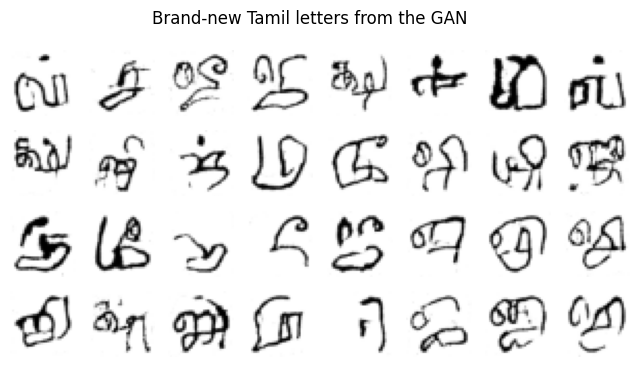

In [7]:
generator.eval()
show(generator(torch.randn(32, NOISE, device=device)), "Brand-new Tamil letters from the GAN")